# Livro de ocorrências digital – CRISP-DM aplicado ao livro de um condomínio do DF

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ram0ng1/Ciencia_de_Dados_Aprendizagem_Maquina/blob/main/Projeto_Ciencia_de_Dados/notebooks/crispdm_livro_ocorrencias.ipynb)

**Disciplina:** Ciência de Dados e Aprendizagem de Máquina – A1 · **Docente:** Profa. Dra. Kadidja Valéria Reginaldo de Oliveira · **UDF – Sistemas de Informação – 2026.2**

**Autor deste notebook:** Ramon Guilherme Marques do Nascimento (dados e análise) · **Projeto em dupla com:** Arthur Rodrigues de Souza Vieira (sistema e painel)

Este notebook é a parte prática do projeto definido na Unidade III
([Definição do Projeto](../../Unidade_3_Gestao_de_Projetos_em_Ciencia_de_Dados/Definicao-Projeto-Ciencia-de-Dados.md)):
substituir o **livro de ocorrências em papel** de um condomínio residencial do DF por um registro digital com painel de
indicadores para o síndico. Aqui percorro as seis fases do CRISP-DM sobre a **transcrição anonimizada** do livro.

| Pergunta | Técnica |
|---|---|
| **P1.** Quais ocorrências mais se repetem, onde, quando, e quais voltam no mesmo local em até 30 dias? (perguntas de negócio 1, 3 e 4) | Pareto, mapa de calor, taxa de recorrência |
| **P2.** Quantas ocorrências recebem resposta, em quanto tempo, e quais tendem a ficar **sem resposta**? (pergunta de negócio 2) | Indicadores, regressão linear e classificadores (regressão logística, árvore, Random Forest) |

> **Dados simulados.** A transcrição do livro real ainda depende da autorização do síndico e da consulta ao CEP
> (Definição do Projeto, Seção 8.1). Para desenvolver e testar o método antes da coleta, a base é **gerada aqui**, com
> exatamente as colunas do dicionário de dados planejado e com os problemas que se esperam de um livro escrito à mão
> (registros sem hora, ilegíveis, duplicados, categorias escritas de formas diferentes). Os números demonstram o
> método e **não descrevem nenhum condomínio real**. Quando a transcrição real chegar, basta trocar a Seção 2.1 pela
> leitura do CSV.

**Como executar:** no Colab, *Ambiente de execução → Executar tudo*. O notebook é autossuficiente: gera os dados, salva os
CSVs em `dados/` e as páginas do dashboard em `Dashboard/`.

In [1]:
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (recall_score, precision_score, f1_score, roc_auc_score, confusion_matrix,
                             RocCurveDisplay, cohen_kappa_score)

warnings.filterwarnings('ignore')
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', font_scale=0.95)
SEED = 42
rng = np.random.default_rng(SEED)

# No repositório o notebook fica em notebooks/; no Colab roda na pasta atual.
BASE = '..' if os.path.exists('../livro_ocorrencias.sql') else '.'
DADOS = os.path.join(BASE, 'dados')
DASH = os.path.join(BASE, 'Dashboard')
os.makedirs(os.path.join(DADOS, 'processed'), exist_ok=True)
os.makedirs(DASH, exist_ok=True)
print('Saídas em:', os.path.abspath(BASE))

Saídas em: /home/user/ciencia_de_dados_aprendizagem_maquina/Projeto_Ciencia_de_Dados


## Fase 1 – Entendimento do negócio (resumo)

**Situação** (Definição do Projeto, Seção 3): no condomínio estudado – prédio antigo, sem administradora digital – o
único canal formal é um livro na portaria. O síndico só sabe o que acontece quando folheia o livro; o morador
não sabe se houve resposta; qualquer pessoa lê as ocorrências dos outros.

| Objetivo de negócio | Meta técnica | Critério de sucesso (definido antes da análise) |
|---|---|---|
| Priorizar manutenções e comunicados (PN 1, 3, 4) | Pareto por categoria e local, mapa de calor e recorrência em 30 dias | Indicadores reproduzidos em SQL com os mesmos valores (o painel do Arthur usa o SQL) |
| Definir prazo de resposta (PN 2) | Taxa de resposta e mediana de dias até a resposta | Indicadores calculados sobre a base limpa, com a regra de limpeza documentada |
| Avisar o síndico das ocorrências com risco de ficar sem resposta (apoio ao PN 2) | Classificador "sem resposta registrada" no momento do registro | Recall ≥ 0,70, AUC ≥ 0,70 e F1 acima do modelo de referência, em teste temporal |
| Garantir uma base confiável e anônima (Objetivo específico 1) | Categorização em dupla e verificação de identificadores | Concordância ≥ 80% e 0 identificadores na base final |

**Unidade de análise:** a **ocorrência** (um registro do livro). **Hipóteses** (Definição, Seção 7): H1 – poucas
categorias concentram a maioria; H2 – a maioria não tem resposta registrada; H3 – barulho concentra-se à noite e nos
fins de semana. H4 (questionário) e H5 (piloto) dependem de coletas que ainda não foram feitas e **não são simuladas
aqui** – não faz sentido inventar respostas de moradores.

> **Escopo.** O sistema do projeto **não** usa aprendizado de máquina (Definição, Seção 9). O classificador da P2 é um
> estudo desta disciplina: mostra se o risco de ficar sem resposta é previsível e quais fatores pesam. O resultado vira
> **regra simples** no painel (por exemplo, destacar ocorrências de barulho registradas à noite) ou trabalho futuro.

## Fase 2 – Entendimento dos dados

### 2.1 Coleta dos dados iniciais (geração da base simulada)

Colunas do dicionário de dados planejado para a transcrição: `id_registro`, `data`, `hora`, `registrado_por`, `local`,
`categoria_livro` (como estava escrito), `resumo` (texto neutro, sem nomes), `houve_resposta`, `data_resposta`,
`desfecho`. Período: **24 meses**, de nov./2024 a out./2026.

Regras usadas para simular (só para a simulação; o modelo não as vê):
- barulho à noite e nos fins de semana, mais em dezembro/janeiro (festas);
- vazamentos na estação chuvosa do DF (outubro a abril);
- a chance de resposta depende da categoria, de quem registrou, do horário e de quantas ocorrências o síndico já
  tem no mês;
- o "andar" é genérico (1º a 6º) e serve só para a simulação: a estrutura do prédio real será conhecida na visita.

In [2]:
CATEGORIAS = {
    # categoria: (peso, locais e pesos, chance de resposta-base, dias médios até a resposta, variações escritas no livro)
    'Barulho':                (.23, {'Unidade': 6, 'Salão de festas': 2, 'Pilotis': 1.5, 'Área de lazer': 1}, .15, 5,
                               ['barulho', 'Barulho', 'som alto', 'festa', 'BARULHO', 'música alta']),
    'Garagem e vagas':        (.15, {'Garagem': 10}, .40, 6, ['garagem', 'vaga', 'carro na vaga', 'Garagem']),
    'Vazamento e infiltração':(.12, {'Unidade': 4, 'Garagem': 2, 'Escadas': 1.5, 'Telhado e caixa d\'água': 2},
                               .75, 3, ['vazamento', 'infiltração', 'Vazamento', 'goteira', 'infiltracao']),
    'Manutenção':             (.13, {'Elevador': 4, 'Portaria': 2, 'Escadas': 2, 'Pilotis': 1, 'Portão': 1.5},
                               .70, 4, ['manutenção', 'elevador parado', 'lâmpada queimada', 'interfone', 'Manutencao']),
    'Lixo e limpeza':         (.09, {'Lixeira': 5, 'Pilotis': 2, 'Escadas': 2}, .35, 4,
                               ['lixo', 'sujeira', 'Lixo', 'limpeza']),
    'Animais':                (.08, {'Pilotis': 3, 'Elevador': 2, 'Área de lazer': 2, 'Unidade': 1}, .20, 7,
                               ['cachorro', 'animal', 'cão sem coleira', 'Animais']),
    'Convivência e regras':   (.09, {'Pilotis': 2, 'Salão de festas': 2, 'Unidade': 2, 'Área de lazer': 1},
                               .25, 8, ['obra fora de horário', 'fumando no hall', 'regimento', 'convivência']),
    'Segurança e acesso':     (.07, {'Portaria': 3, 'Portão': 3, 'Garagem': 2}, .60, 3,
                               ['portão aberto', 'segurança', 'estranho no prédio', 'Seguranca']),
    'Encomendas e portaria':  (.04, {'Portaria': 6}, .45, 2, ['encomenda', 'entrega extraviada', 'portaria']),
}
LOCAIS = ['Unidade', 'Garagem', 'Pilotis', 'Portaria', 'Portão', 'Escadas', 'Elevador', 'Salão de festas',
          'Área de lazer', 'Lixeira', "Telhado e caixa d'água"]
RESUMOS = {
    'Barulho': ['Som alto vindo de unidade do {a} andar', 'Festa no salão após o horário', 'Barulho de arrastar móveis',
                'Gritaria nos pilotis de madrugada', 'Música alta em unidade do {a} andar'],
    'Garagem e vagas': ['Carro estacionado em vaga de outro morador', 'Veículo bloqueando a saída',
                        'Moto ocupando duas vagas', 'Carro de visitante na garagem'],
    'Vazamento e infiltração': ['Infiltração no teto do banheiro de unidade do {a} andar', 'Vazamento na garagem',
                                'Goteira na escada', 'Água escorrendo da caixa d\'água', 'Mancha de umidade na parede'],
    'Manutenção': ['Elevador parado', 'Lâmpada queimada na escada', 'Interfone sem funcionar', 'Portão travando',
                   'Luz dos pilotis apagada'],
    'Lixo e limpeza': ['Lixo deixado fora da lixeira', 'Escada suja', 'Lixeira transbordando', 'Entulho nos pilotis'],
    'Animais': ['Cachorro sem coleira nos pilotis', 'Fezes de animal no elevador', 'Latidos constantes'],
    'Convivência e regras': ['Obra fora do horário permitido', 'Pessoa fumando no hall', 'Uso do salão sem reserva',
                             'Bicicleta no corredor'],
    'Segurança e acesso': ['Portão encontrado aberto', 'Pessoa estranha no prédio', 'Câmera da garagem desligada'],
    'Encomendas e portaria': ['Encomenda entregue na unidade errada', 'Entrega extraviada', 'Demora no interfone'],
}
DESFECHOS = {'Manutenção': 'Técnico acionado e reparo feito', 'Vazamento e infiltração': 'Encanador vistoriou e corrigiu',
             'Barulho': 'Morador advertido', 'Garagem e vagas': 'Proprietário do veículo notificado',
             'Lixo e limpeza': 'Zeladoria limpou e afixou aviso', 'Animais': 'Tutor orientado sobre o regimento',
             'Convivência e regras': 'Advertência conforme o regimento', 'Segurança e acesso': 'Portaria orientada',
             'Encomendas e portaria': 'Encomenda localizada e entregue'}
nomes_cat = list(CATEGORIAS)
peso_cat = np.array([CATEGORIAS[c][0] for c in nomes_cat]); peso_cat /= peso_cat.sum()

def sortear_hora(cat, fim_semana):
    if cat == 'Barulho' and rng.random() < .72:
        return int(rng.choice([22, 23, 0, 1, 2, 3]))
    if cat in ('Convivência e regras', 'Animais') and rng.random() < .35:
        return int(rng.choice([19, 20, 21, 22]))
    return int(np.clip(rng.normal(13 if not fim_semana else 15, 3.5), 6, 21))

registros = []
dias = pd.date_range('2024-11-01', '2026-10-31', freq='D')
carga_mes = {}
for dia in dias:
    mes_chuva = dia.month in (10, 11, 12, 1, 2, 3, 4)
    taxa = .78 * (1.25 if dia.month in (12, 1) else 1) * (1.15 if dia.dayofweek >= 5 else 1)
    for _ in range(rng.poisson(taxa)):
        p = peso_cat.copy()
        p[nomes_cat.index('Vazamento e infiltração')] *= 1.9 if mes_chuva else .5
        p[nomes_cat.index('Barulho')] *= 1.5 if dia.dayofweek >= 4 else .8
        cat = rng.choice(nomes_cat, p=p / p.sum())
        _, locs, p_resp, dias_resp, variantes = CATEGORIAS[cat]
        fim_semana = dia.dayofweek >= 5
        hora = sortear_hora(cat, fim_semana)
        local = rng.choice(list(locs), p=np.array(list(locs.values())) / sum(locs.values()))
        quem = rng.choice(['Portaria', 'Morador', 'Zeladoria', 'Síndico'], p=[.50, .35, .10, .05])
        chave = dia.to_period('M')
        carga_mes[chave] = carga_mes.get(chave, 0) + 1
        # chance de resposta registrada
        pr = p_resp + (.20 if quem in ('Síndico', 'Zeladoria') else -.05 if quem == 'Morador' else 0)
        pr += -.15 if (hora >= 22 or hora < 6) else 0
        pr += -.03 * max(0, carga_mes[chave] - 12)
        respondeu = rng.random() < np.clip(pr, .03, .95)
        espera = None
        if respondeu:
            fator = (1 + .07 * max(0, carga_mes[chave] - 12))
            espera = int(np.ceil(rng.gamma(1.6, dias_resp * fator / 1.6)))
        andar = int(rng.integers(1, 7))
        resumo = rng.choice(RESUMOS[cat]).format(a=f'{andar}º')
        if local == 'Unidade':
            local = f'Unidade ({andar}º andar)'  # só o andar, nunca o número do apartamento
        registros.append({'data': dia, 'hora': f'{hora:02d}:{int(rng.integers(0, 60)):02d}', 'registrado_por': quem,
                          'local': local, 'categoria_livro': rng.choice(variantes), 'categoria_real': cat,
                          'resumo': resumo, 'houve_resposta': 'sim' if respondeu else 'não',
                          'data_resposta': dia + pd.Timedelta(days=espera) if respondeu else pd.NaT,
                          'desfecho': DESFECHOS[cat] if respondeu else ''})
        # problema que volta no mesmo local (vazamento e manutenção mal resolvidos)
        if cat in ('Vazamento e infiltração', 'Manutenção', 'Lixo e limpeza') and rng.random() < .22:
            volta = dia + pd.Timedelta(days=int(rng.integers(3, 30)))
            if volta <= dias[-1]:
                registros.append({**registros[-1], 'data': volta,
                                  'hora': f'{int(np.clip(rng.normal(13, 3), 6, 21)):02d}:{int(rng.integers(0, 60)):02d}',
                                  'resumo': registros[-1]['resumo'] + ' novamente', 'houve_resposta': 'não',
                                  'data_resposta': pd.NaT, 'desfecho': ''})

livro = pd.DataFrame(registros).sort_values(['data', 'hora']).reset_index(drop=True)
print(len(livro), 'ocorrências simuladas')
print(livro.categoria_real.value_counts().to_string())

639 ocorrências simuladas
categoria_real
Barulho                    143
Manutenção                  97
Vazamento e infiltração     91
Garagem e vagas             89
Convivência e regras        54
Lixo e limpeza              51
Animais                     51
Segurança e acesso          39
Encomendas e portaria       24


Agora entram os **problemas de um livro escrito à mão**, como previstos na Definição (Seção 8.1), e a
**categorização em dupla**: cada autor lê o resumo e atribui uma das 9 categorias padronizadas; o objetivo
específico 1 pede concordância ≥ 80%.

In [3]:
livro.insert(0, 'id_registro', np.arange(1, len(livro) + 1))
livro['data'] = livro.data.dt.strftime('%Y-%m-%d')
livro['data_resposta'] = livro.data_resposta.dt.strftime('%Y-%m-%d')
n = len(livro)
def sortear(k, semente):
    return livro.sample(k, random_state=semente).index

livro.loc[sortear(int(n * .08), 1), 'hora'] = np.nan                      # hora não anotada
livro.loc[sortear(int(n * .05), 2), 'local'] = np.nan                     # local não anotado
ileg = sortear(int(n * .035), 3)
livro.loc[ileg, ['resumo', 'categoria_livro']] = ['[ilegível]', np.nan]    # registro ilegível
resp_idx = livro.index[livro.houve_resposta == 'sim']
livro.loc[livro.loc[resp_idx].sample(7, random_state=4).index, 'data_resposta'] = '2024-10-15'  # resposta antes do registro
livro.loc[livro.loc[resp_idx].sample(12, random_state=5).index, 'data_resposta'] = np.nan       # "respondido" sem data
erro_ano = sortear(5, 6)
livro.loc[erro_ano, 'data'] = livro.loc[erro_ano, 'data'].str.replace('2025', '2052').str.replace('2026', '2062')
vaz = livro.loc[sortear(4, 7)]
livro.loc[vaz.index, 'resumo'] = [r + ' (apto ' + str(rng.integers(101, 607)) + ')' for r in vaz.resumo]  # identificador vazado
# a mesma ocorrência anotada duas vezes (portaria e morador)
dup = livro.sample(16, random_state=8).copy()
dup['registrado_por'] = np.where(dup.registrado_por == 'Portaria', 'Morador', 'Portaria')
livro = pd.concat([livro, dup]).sort_values(['data', 'id_registro']).reset_index(drop=True)
livro['id_registro'] = np.arange(1, len(livro) + 1)

# categorização em dupla: cada autor erra/diverge em parte dos casos ambíguos
def categorizar(semente, taxa_erro):
    r = np.random.default_rng(semente)
    cat = livro.categoria_real.copy()
    trocar = r.random(len(cat)) < taxa_erro
    vizinhas = {'Barulho': 'Convivência e regras', 'Convivência e regras': 'Barulho', 'Garagem e vagas': 'Segurança e acesso',
                'Segurança e acesso': 'Garagem e vagas', 'Vazamento e infiltração': 'Manutenção',
                'Manutenção': 'Vazamento e infiltração', 'Lixo e limpeza': 'Convivência e regras',
                'Animais': 'Convivência e regras', 'Encomendas e portaria': 'Segurança e acesso'}
    cat[trocar] = cat[trocar].map(vizinhas)
    cat[livro.resumo == '[ilegível]'] = 'Não identificada'
    return cat
livro['categoria_ramon'] = categorizar(10, .07)
livro['categoria_arthur'] = categorizar(11, .08)
# reunião de consenso: onde a dupla divergiu, os dois releem o resumo e decidem juntos
livro['categoria_consenso'] = np.where(livro.categoria_ramon == livro.categoria_arthur, livro.categoria_ramon,
                                       livro.categoria_real)
livro.loc[livro.resumo == '[ilegível]', 'categoria_consenso'] = 'Não identificada'
livro = livro.drop(columns='categoria_real')
livro.to_csv(os.path.join(DADOS, 'livro_ocorrencias_transcrito.csv'), index=False)
print(livro.shape)
livro.head(8)

(655, 13)


,id_registro,data,hora,registrado_por,local,categoria_livro,resumo,houve_resposta,data_resposta,desfecho,categoria_ramon,categoria_arthur,categoria_consenso
0,1,2024-11-01,06:50,Morador,Área de lazer,fumando no hall,Obra fora do horário permitido,não,NaN,,Convivência e regras,Convivência e regras,Convivência e regras
1,2,2024-11-03,03:21,Morador,NaN,barulho,Gritaria nos pilotis de madrugada,não,NaN,,Barulho,Barulho,Barulho
2,3,2024-11-03,13:58,Portaria,Salão de festas,fumando no hall,Pessoa fumando no hall,sim,2024-11-13,Advertência conforme o regimento,Convivência e regras,Convivência e regras,Convivência e regras
3,4,2024-11-03,17:13,Portaria,Garagem,carro na vaga,Veículo bloqueando a saída,não,NaN,,Garagem e vagas,Segurança e acesso,Garagem e vagas
4,5,2024-11-05,11:28,Morador,Lixeira,limpeza,Lixeira transbordando,sim,2024-10-15,Zeladoria limpou e afixou aviso,Lixo e limpeza,Lixo e limpeza,Lixo e limpeza
5,6,2024-11-05,13:47,Morador,Salão de festas,convivência,Bicicleta no corredor,sim,2024-11-16,Advertência conforme o regimento,Convivência e regras,Convivência e regras,Convivência e regras
6,7,2024-11-06,15:14,Portaria,Elevador,Manutencao,Elevador parado,sim,NaN,Técnico acionado e reparo feito,Manutenção,Vazamento e infiltração,Manutenção
7,8,2024-11-08,11:27,Portaria,Área de lazer,cão sem coleira,Latidos constantes,sim,2024-11-12,Tutor orientado sobre o regimento,Animais,Animais,Animais


### 2.2 Descrição dos dados (volume, tipos, período)

In [4]:
print(livro.dtypes.to_string(), '\n')
print('Registros:', len(livro), '· período escrito no livro:', livro.data.min(), '→', livro.data.max())
print('\nQuem registrou:\n', livro.registrado_por.value_counts(normalize=True).round(3).to_string())
print('\nComo a categoria aparece escrita no livro (15 formas mais comuns de', livro.categoria_livro.nunique(), '):')
print(livro.categoria_livro.value_counts().head(15).to_string())

id_registro           int64
data                    str
hora                    str
registrado_por          str
local                   str
categoria_livro         str
resumo                  str
houve_resposta          str
data_resposta           str
desfecho                str
categoria_ramon         str
categoria_arthur        str
categoria_consenso      str 

Registros: 655 · período escrito no livro: 2024-11-01 → 2062-05-16

Quem registrou:
 registrado_por
Portaria     0.548
Morador      0.336
Zeladoria    0.082
Síndico      0.034

Como a categoria aparece escrita no livro (15 formas mais comuns de 39 ):
categoria_livro
garagem             29
Barulho             28
lâmpada queimada    26
música alta         26
festa               26
BARULHO             25
Manutencao          24
interfone           24
carro na vaga       23
goteira             23
Garagem             22
barulho             21
convivência         18
Vazamento           18
infiltracao         17


A coluna `categoria_livro` mostra por que a categorização é necessária: a mesma coisa aparece escrita de várias
formas ("barulho", "som alto", "festa"...). Por isso a análise usa a categoria **padronizada** pela dupla.

### 2.3 Verificação da qualidade dos dados

In [5]:
dt = pd.to_datetime(livro.data, errors='coerce')
dr = pd.to_datetime(livro.data_resposta, errors='coerce')
padrao_id = re.compile(r'\b(apto|ap\.?|apartamento)\s*\d{3}\b|\b[A-Z]{3}-?\d[A-Z0-9]\d{2}\b', re.I)
chave_dup = ['data', 'hora', 'local', 'resumo']
qualidade = pd.Series({
    'V1 – sem hora': int(livro.hora.isna().sum()),
    'V2 – sem local': int(livro.local.isna().sum()),
    'V3 – ilegível': int((livro.resumo == '[ilegível]').sum()),
    'V4 – data fora do período (nov./2024–out./2026)': int(((dt < '2024-11-01') | (dt > '2026-10-31')).sum()),
    'V5 – resposta antes do registro ou "sim" sem data': int(((dr < dt) | ((livro.houve_resposta == 'sim') & dr.isna())).sum()),
    'V6 – possível identificador no resumo (apto/placa)': int(livro.resumo.str.contains(padrao_id).sum()),
    'V7 – registro duplicado (mesma data, hora, local e resumo)': int(livro.duplicated(chave_dup).sum()),
})
print(qualidade.to_string())
concord = (livro.categoria_ramon == livro.categoria_arthur).mean()
kappa = cohen_kappa_score(livro.categoria_ramon, livro.categoria_arthur)
print(f'\nConcordância da categorização em dupla: {concord:.1%} (kappa de Cohen = {kappa:.2f})')
pd.crosstab(livro.categoria_ramon, livro.categoria_arthur)

V1 – sem hora                                                 51
V2 – sem local                                                32
V3 – ilegível                                                 23
V4 – data fora do período (nov./2024–out./2026)                4
V5 – resposta antes do registro ou "sim" sem data             21
V6 – possível identificador no resumo (apto/placa)             4
V7 – registro duplicado (mesma data, hora, local e resumo)    16



Concordância da categorização em dupla: 86.1% (kappa de Cohen = 0.84)


categoria_arthur,Animais,Barulho,Convivência e regras,Encomendas e portaria,Garagem e vagas,Lixo e limpeza,Manutenção,Não identificada,Segurança e acesso,Vazamento e infiltração
categoria_ramon,,,,,,,,,,
Animais,40,0,7,0,0,0,0,0,0,0
Barulho,0,125,14,0,0,0,0,0,0,0
Convivência e regras,4,10,44,0,0,1,0,0,0,0
Encomendas e portaria,0,0,0,19,0,0,0,0,4,0
Garagem e vagas,0,0,0,0,83,0,0,0,8,0
Lixo e limpeza,0,0,2,0,0,46,0,0,0,0
Manutenção,0,0,0,0,0,0,77,0,0,23
Não identificada,0,0,0,0,0,0,0,23,0,0
Segurança e acesso,0,0,0,1,5,0,0,0,32,0


**Leitura da qualidade:** V1–V3 são a "cara" de um livro à mão – a falta de qualidade é **um achado do diagnóstico**,
não só um problema técnico (Definição, Seção 8). V4 e V5 são erros de anotação ou transcrição. V6 é grave: a
transcrição deveria ser anônima e 4 resumos citam o apartamento. V7 é a mesma ocorrência registrada pela portaria e pelo
morador. A concordância passa da meta de 80%; as divergências ficam entre categorias vizinhas (barulho × convivência,
vazamento × manutenção) e são resolvidas na **reunião de consenso** (coluna `categoria_consenso`).

## Fase 3 – Preparação dos dados

Sequência: **Selecionar → Limpar → Construir → Integrar.** A mesma limpeza está na view `ocorrencias_limpas` do arquivo
`livro_ocorrencias.sql`, para que o painel do sistema calcule os mesmos números.

### 3.1 Selecionar e 3.2 Limpar

In [6]:
df = livro.copy()
log = {}
df['resumo'] = df.resumo.str.replace(padrao_id, '(unidade)', regex=True); log['identificador removido'] = int(qualidade.iloc[5])
n0 = len(df); df = df[~df.duplicated(chave_dup)]; log['duplicados removidos'] = n0 - len(df)
df['data'] = pd.to_datetime(df.data, errors='coerce')
# ano trocado na transcrição (2052, 2062): a ordem do livro mostra o ano certo → corrige o século/dígito
fora = (df.data > '2026-10-31')
df.loc[fora, 'data'] = df.loc[fora, 'data'].apply(lambda d: d.replace(year=2025 if d.year == 2052 else 2026))
log['ano corrigido'] = int(fora.sum())
df['data_resposta'] = pd.to_datetime(df.data_resposta, errors='coerce')
invalida = (df.data_resposta < df.data)
df.loc[invalida, 'data_resposta'] = pd.NaT; log['data de resposta inválida → vazia'] = int(invalida.sum())
# categoria final = consenso da dupla; ilegíveis ficam como "Não identificada"
df['categoria'] = df.categoria_consenso
df['local'] = df.local.fillna('Não informado')
print(log, '→ base limpa:', len(df), 'ocorrências')

{'identificador removido': 4, 'duplicados removidos': 16, 'ano corrigido': 4, 'data de resposta inválida → vazia': 7} → base limpa: 639 ocorrências


### 3.3 Construir e 3.4 Integrar

Atributos derivados (todos conhecidos **no momento do registro**, exceto os de resposta):
- `dia_semana`, `fim_de_semana`, `faixa_horaria`, `noturno` (22h–6h), `mes`, `estacao_chuvosa` (out.–abr.);
- `carga_30d`: quantas ocorrências o livro já tinha nos 30 dias anteriores (o quanto o síndico está ocupado);
- `recorrente`: houve a mesma categoria no mesmo local nos 30 dias anteriores (pergunta de negócio 4);
- `completo`: data, hora, local e categoria legíveis;
- `sem_resposta` (alvo da P2) e `dias_ate_resposta`.

In [7]:
df['hora_num'] = pd.to_numeric(df.hora.str[:2], errors='coerce')
df['dia_semana'] = df.data.dt.dayofweek
df['fim_de_semana'] = df.dia_semana >= 5
df['noturno'] = (df.hora_num >= 22) | (df.hora_num < 6)
df['faixa_horaria'] = pd.cut(df.hora_num, [-1, 5, 11, 17, 21, 23], labels=['0h–6h', '6h–12h', '12h–18h', '18h–22h', '22h–24h'])
df['mes'] = df.data.dt.to_period('M')
df['estacao_chuvosa'] = df.data.dt.month.isin([10, 11, 12, 1, 2, 3, 4])
df = df.sort_values(['data', 'hora_num'], kind='stable').reset_index(drop=True)  # empate: ordem do livro
datas = df.data.values
df['carga_30d'] = [int(((datas >= d - np.timedelta64(30, 'D')) & (datas < d)).sum()) for d in datas]
df['recorrente'] = False
for (cat, loc), g in df[df.local != 'Não informado'].groupby(['categoria', 'local']):
    anteriores = g.data.values
    for i, idx in enumerate(g.index):
        df.loc[idx, 'recorrente'] = bool(((anteriores[:i] >= anteriores[i] - np.timedelta64(30, 'D'))).any())
df['completo'] = df.hora.notna() & (df.local != 'Não informado') & (df.categoria != 'Não identificada')
df['sem_resposta'] = (df.houve_resposta == 'não').astype(int)
df['dias_ate_resposta'] = (df.data_resposta - df.data).dt.days
print(df[['data', 'hora', 'categoria', 'local', 'noturno', 'carga_30d', 'recorrente', 'completo', 'sem_resposta',
          'dias_ate_resposta']].head(8).to_string(index=False))

      data  hora            categoria           local  noturno  carga_30d  recorrente  completo  sem_resposta  dias_ate_resposta
2024-11-01 06:50 Convivência e regras   Área de lazer    False          0       False      True             1                NaN
2024-11-03 03:21              Barulho   Não informado     True          1       False     False             1                NaN
2024-11-03 13:58 Convivência e regras Salão de festas    False          1       False      True             0               10.0
2024-11-03 17:13      Garagem e vagas         Garagem    False          1       False      True             1                NaN
2024-11-05 11:28       Lixo e limpeza         Lixeira    False          4       False      True             0                NaN
2024-11-05 13:47 Convivência e regras Salão de festas    False          4        True      True             0               11.0
2024-11-06 15:14           Manutenção        Elevador    False          6       False      True  

## Análise exploratória – respostas às perguntas de negócio e hipóteses

### PN 1 e H1 – Quais ocorrências mais se repetem e onde? (Pareto)

                         ocorrencias  perc  perc_acumulado
categoria                                                 
Barulho                          138  21.6            21.6
Manutenção                        95  14.9            36.5
Garagem e vagas                   88  13.8            50.2
Vazamento e infiltração           88  13.8            64.0
Convivência e regras              50   7.8            71.8
Animais                           49   7.7            79.5
Lixo e limpeza                    48   7.5            87.0
Segurança e acesso                37   5.8            92.8
Encomendas e portaria             24   3.8            96.6
Não identificada                  22   3.4           100.0

H1: as 3 categorias mais frequentes somam 50.2% → confirmada (critério: ≥ 50%)


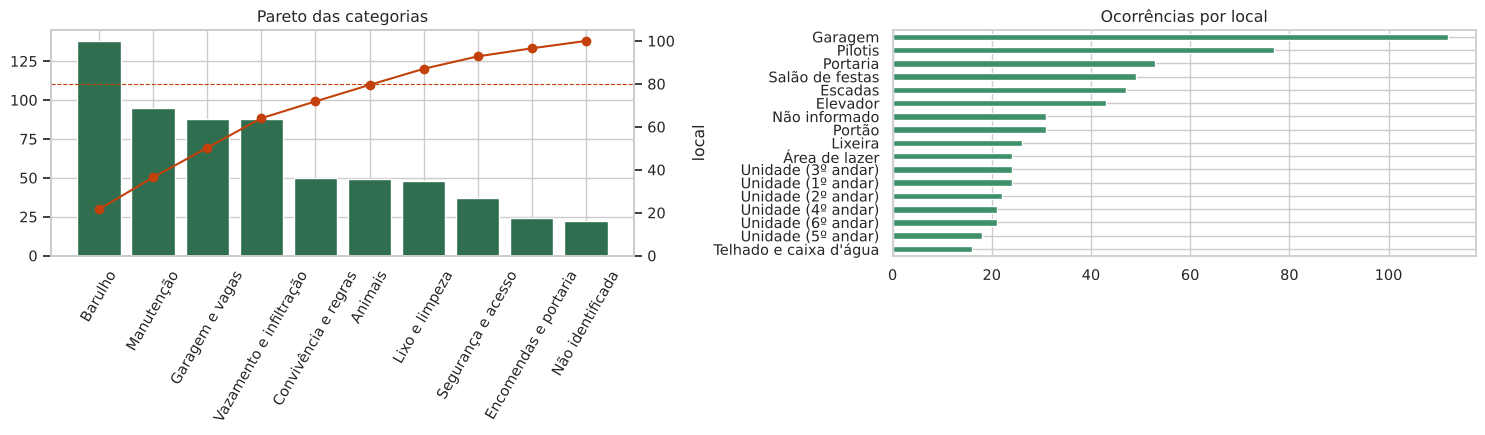

categoria        Animais  Barulho  Convivência e regras  Encomendas e portaria  Garagem e vagas  Lixo e limpeza  Manutenção  Não identificada  Segurança e acesso  Vazamento e infiltração
local                                                                                                                                                                                     
Garagem                0        0                     0                      0               83               0           0                 2                   9                       18
Pilotis               14       22                    17                      0                0               8          14                 2                   0                        0
Portaria               0        0                     0                     23                0               0          19                 1                  10                        0
Salão de festas        0       31                    15          

In [8]:
cat = df.categoria.value_counts()
pareto = pd.DataFrame({'ocorrencias': cat, 'perc': cat / cat.sum() * 100})
pareto['perc_acumulado'] = pareto.perc.cumsum()
print(pareto.round(1).to_string())
top3 = pareto.perc.iloc[:3].sum()
print(f'\nH1: as 3 categorias mais frequentes somam {top3:.1f}% → {"confirmada" if top3 >= 50 else "refutada"} (critério: ≥ 50%)')
loc = df.local.value_counts()
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].bar(pareto.index, pareto.ocorrencias, color='#2f6f4f')
ax2 = ax[0].twinx(); ax2.plot(pareto.index, pareto.perc_acumulado, color='#c2410c', marker='o'); ax2.set_ylim(0, 105)
ax2.axhline(80, ls='--', color='#c2410c', lw=.8); ax2.grid(False)
ax[0].set_title('Pareto das categorias'); ax[0].tick_params(axis='x', rotation=60)
loc.sort_values().plot.barh(ax=ax[1], color='#3f8f6b'); ax[1].set_title('Ocorrências por local')
plt.tight_layout(); plt.show()
print(pd.crosstab(df.local, df.categoria).loc[loc.index[:6]].to_string())

**Leitura (PN 1 / H1):** Barulho, Manutenção e Garagem somam **50,2%** – a H1 é **confirmada, mas por pouco** (o
critério da Definição é ≥ 50%). Com seis categorias chega-se a ~80%. A **garagem** é o local com mais registros (vagas
ocupadas); salão de festas e pilotis concentram o barulho; elevador e portaria, a manutenção.

### PN 2 e H2 – Quantas recebem resposta e em quanto tempo?

In [9]:
taxa_resp = 1 - df.sem_resposta.mean()
print(f'Taxa de resposta registrada: {taxa_resp:.1%} → H2 {"confirmada" if taxa_resp < .5 else "refutada"} (critério: < 50%)')
print(f'Mediana de dias até a resposta: {df.dias_ate_resposta.median():.0f} · percentil 90: '
      f'{df.dias_ate_resposta.quantile(.9):.0f} · maior: {df.dias_ate_resposta.max():.0f} dias')
resp_cat = df.groupby('categoria').agg(ocorrencias=('id_registro', 'size'), taxa_resposta=('sem_resposta', lambda s: 1 - s.mean()),
                                       mediana_dias=('dias_ate_resposta', 'median')).sort_values('taxa_resposta')
print(resp_cat.round(2).to_string())
por_quem = df.groupby('registrado_por').agg(ocorrencias=('id_registro', 'size'), taxa_resposta=('sem_resposta', lambda s: 1 - s.mean()),
                                           mediana_dias=('dias_ate_resposta', 'median')).sort_values('taxa_resposta')
print('\n', por_quem.round(2).to_string())

Taxa de resposta registrada: 30.0% → H2 confirmada (critério: < 50%)
Mediana de dias até a resposta: 4 · percentil 90: 11 · maior: 40 dias
                         ocorrencias  taxa_resposta  mediana_dias
categoria                                                        
Barulho                          138           0.03           6.5
Animais                           49           0.10           6.0
Não identificada                  22           0.18           4.0
Lixo e limpeza                    48           0.19           3.5
Garagem e vagas                   88           0.28           6.0
Convivência e regras              50           0.32           9.5
Encomendas e portaria             24           0.38           2.0
Segurança e acesso                37           0.43           3.0
Vazamento e infiltração           88           0.51           4.0
Manutenção                        95           0.62           5.0

                 ocorrencias  taxa_resposta  mediana_dias
registrado

**Leitura (PN 2 / H2):** só **30%** das ocorrências têm resposta registrada – H2 **confirmada**. Quando há resposta, a
mediana é de **4 dias** (90% em até 11 dias). Manutenção (62%) e vazamento (51%) – algo a consertar – são as mais
respondidas; **barulho, a categoria mais frequente, tem só 3%**. Registros da zeladoria são respondidos com mais
frequência (54%) do que os de moradores (26%).

### PN 3 e H3 – Em que dias e horários as ocorrências acontecem?

H3: 85.0% das ocorrências de barulho foram entre 22h e 6h ou no fim de semana → confirmada (critério: ≥ 50%)


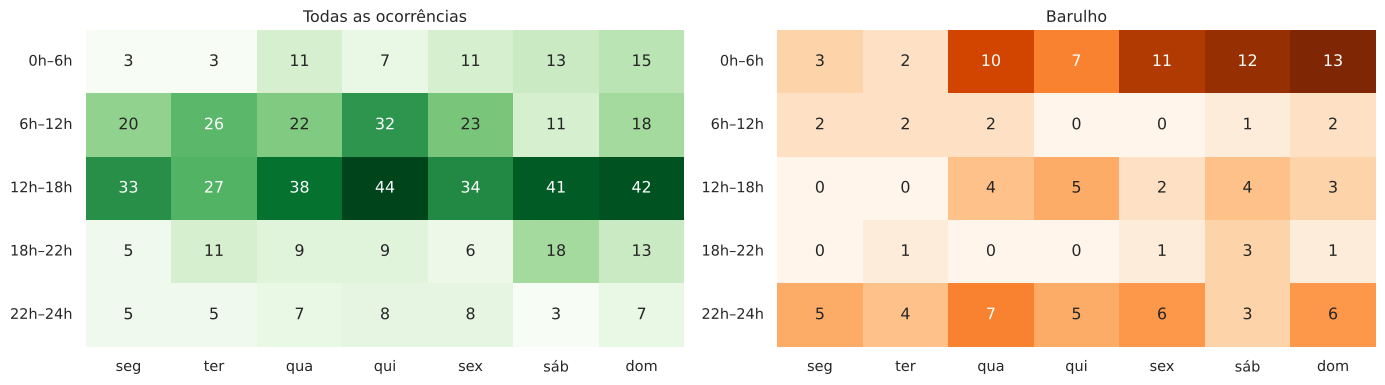

In [10]:
dias_nome = ['seg', 'ter', 'qua', 'qui', 'sex', 'sáb', 'dom']
calor = df.dropna(subset=['hora_num']).pivot_table(index='faixa_horaria', columns='dia_semana', values='id_registro',
                                                   aggfunc='count', observed=False).reindex(columns=range(7)).fillna(0)
calor.columns = dias_nome
barulho = df[(df.categoria == 'Barulho') & df.hora_num.notna()]
h3 = (barulho.noturno | barulho.fim_de_semana).mean()
print(f'H3: {h3:.1%} das ocorrências de barulho foram entre 22h e 6h ou no fim de semana → '
      f'{"confirmada" if h3 >= .5 else "refutada"} (critério: ≥ 50%)')
calor_b = barulho.pivot_table(index='faixa_horaria', columns='dia_semana', values='id_registro', aggfunc='count',
                              observed=False).reindex(columns=range(7)).fillna(0)
calor_b.columns = dias_nome
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.heatmap(calor, annot=True, fmt='.0f', cmap='Greens', ax=ax[0], cbar=False); ax[0].set_title('Todas as ocorrências')
sns.heatmap(calor_b, annot=True, fmt='.0f', cmap='Oranges', ax=ax[1], cbar=False); ax[1].set_title('Barulho')
for a in ax: a.set_xlabel(''); a.set_ylabel('')
plt.tight_layout(); plt.show()

### PN 4 – Há problemas que voltam no mesmo local em até 30 dias?

In [11]:
recor = df.groupby('categoria').recorrente.mean().sort_values(ascending=False)
print(f'Taxa de recorrência geral (mesma categoria e local em até 30 dias): {df.recorrente.mean():.1%}')
print(recor.round(3).to_string())
top_rec = (df[df.recorrente].groupby(['categoria', 'local']).size().sort_values(ascending=False).head(6))
print('\nPares categoria × local que mais voltam:\n', top_rec.to_string())

Taxa de recorrência geral (mesma categoria e local em até 30 dias): 50.1%
categoria
Garagem e vagas            0.909
Encomendas e portaria      0.625
Manutenção                 0.505
Segurança e acesso         0.459
Vazamento e infiltração    0.455
Barulho                    0.442
Lixo e limpeza             0.417
Convivência e regras       0.400
Animais                    0.327
Não identificada           0.136

Pares categoria × local que mais voltam:
 categoria              local          
Garagem e vagas        Garagem            80
Barulho                Salão de festas    21
                       Pilotis            15
Encomendas e portaria  Portaria           15
Manutenção             Elevador           15
Lixo e limpeza         Lixeira            14


**Leitura (PN 4):** metade das ocorrências repete a mesma categoria no mesmo local em até 30 dias. Na **garagem**, 91%
são repetições: o conflito de vagas é crônico e pede regra e sinalização, não resposta caso a caso. **Manutenção no
elevador** e **encomendas na portaria** também voltam com frequência – candidatas a ação preventiva.

### 3.5 Diagrama de dispersão com regressão linear

O síndico responde menos quando o livro está cheio? Cada ponto é um **mês**: ocorrências registradas × taxa de
resposta registrada, com a reta de regressão linear.

Taxa de resposta (%) = -0.25 × ocorrências + 37.1 · R² = 0.04 · n = 24 meses
Mediana de dias até a resposta = 0.02 × ocorrências + 4.1 · R² = 0.00


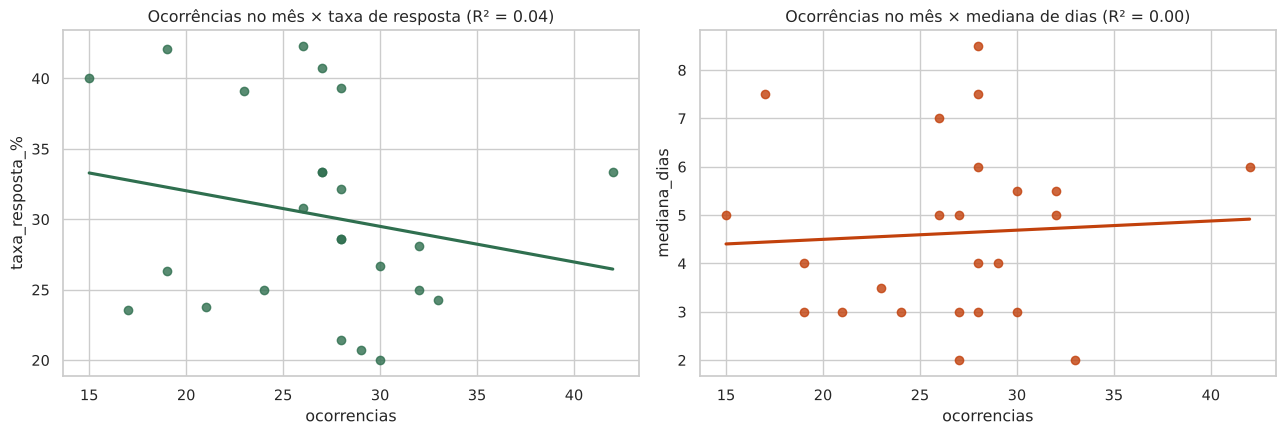

In [12]:
mensal = (df.groupby('mes').agg(ocorrencias=('id_registro', 'size'), mediana_dias=('dias_ate_resposta', 'median'),
                                taxa_resposta=('sem_resposta', lambda s: 1 - s.mean()))
          .reset_index())
mensal['taxa_resposta_%'] = mensal.taxa_resposta * 100
m_all = LinearRegression().fit(mensal[['ocorrencias']], mensal['taxa_resposta_%'])
r2_all = m_all.score(mensal[['ocorrencias']], mensal['taxa_resposta_%'])
print(f'Taxa de resposta (%) = {m_all.coef_[0]:.2f} × ocorrências + {m_all.intercept_:.1f} · R² = {r2_all:.2f} · n = {len(mensal)} meses')
m_d = LinearRegression().fit(mensal[['ocorrencias']], mensal.mediana_dias)
r2_d = m_d.score(mensal[['ocorrencias']], mensal.mediana_dias)
print(f'Mediana de dias até a resposta = {m_d.coef_[0]:.2f} × ocorrências + {m_d.intercept_:.1f} · R² = {r2_d:.2f}')
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.regplot(data=mensal, x='ocorrencias', y='taxa_resposta_%', ax=ax[0], color='#2f6f4f', ci=None)
ax[0].set_title(f'Ocorrências no mês × taxa de resposta (R² = {r2_all:.2f})')
sns.regplot(data=mensal, x='ocorrencias', y='mediana_dias', ax=ax[1], color='#c2410c', ci=None)
ax[1].set_title(f'Ocorrências no mês × mediana de dias (R² = {r2_d:.2f})')
plt.tight_layout(); plt.show()

**Leitura:** nesta base a relação é **praticamente nula** (−0,25 p.p. por ocorrência a mais; R² = 0,04), e o tempo até
a resposta também não muda com o volume (R² ≈ 0). Ou seja, o volume do mês não explica a falta de resposta: o que pesa
é **o tipo** de ocorrência (ver PN 2 e o modelo a seguir). Com dados reais, este teste deve ser refeito.

## Fase 4 – Modelagem

### 4.1 Classificação: a ocorrência vai ficar sem resposta registrada? (P2)

**Atributos** (todos existem no momento do registro): categoria, local, quem registrou, noturno, fim de semana, estação
chuvosa, carga dos últimos 30 dias, recorrente e completo. **Alvo:** `sem_resposta`.

**Teste temporal:** treino com nov./2024–abr./2026 (18 meses) e teste com mai.–out./2026 (6 meses). Nada do futuro entra
no treino. A referência (`DummyClassifier` estratificado) sorteia a classe na proporção do treino.

In [13]:
cat_cols = ['categoria', 'local', 'registrado_por']
num_cols = ['noturno', 'fim_de_semana', 'estacao_chuvosa', 'carga_30d', 'recorrente', 'completo']
dados = df.copy()
for c in num_cols:
    dados[c] = dados[c].astype(float)
corte = pd.Timestamp('2026-05-01')
treino, teste = dados[dados.data < corte], dados[dados.data >= corte]
Xtr, ytr, Xte, yte = treino[cat_cols + num_cols], treino.sem_resposta, teste[cat_cols + num_cols], teste.sem_resposta
print(f'Treino: {len(treino)} ocorrências ({ytr.mean():.1%} sem resposta) · Teste: {len(teste)} ({yte.mean():.1%} sem resposta)')

def preparo(escalar):
    return ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
                              ('num', StandardScaler() if escalar else 'passthrough', num_cols)])
modelos = {
    'Referência (aleatória)': DummyClassifier(strategy='stratified', random_state=SEED),
    'Regressão logística': make_pipeline(preparo(True), LogisticRegression(max_iter=2000, C=.5, class_weight='balanced')),
    'Árvore de decisão': make_pipeline(preparo(False), DecisionTreeClassifier(max_depth=4, min_samples_leaf=15, class_weight='balanced',
                                                                               random_state=SEED)),
    'Random Forest': make_pipeline(preparo(False), RandomForestClassifier(n_estimators=400, min_samples_leaf=8, class_weight='balanced',
                                                                           random_state=SEED, n_jobs=-1)),
}
linhas = []
for nome, m in modelos.items():
    m.fit(Xtr, ytr)
    p = m.predict(Xte); prob = m.predict_proba(Xte)[:, 1]
    linhas.append({'modelo': nome, 'recall': recall_score(yte, p), 'precisao': precision_score(yte, p, zero_division=0),
                   'f1': f1_score(yte, p), 'auc': roc_auc_score(yte, prob), 'alertas': int(p.sum())})
metricas = pd.DataFrame(linhas).set_index('modelo')
print(metricas.round(3).to_string())

Treino: 487 ocorrências (69.8% sem resposta) · Teste: 152 (70.4% sem resposta)


                        recall  precisao     f1    auc  alertas
modelo                                                         
Referência (aleatória)   0.729     0.736  0.732  0.553      106
Regressão logística      0.720     0.828  0.770  0.794       93
Árvore de decisão        0.832     0.795  0.813  0.766      112
Random Forest            0.748     0.808  0.777  0.791       99


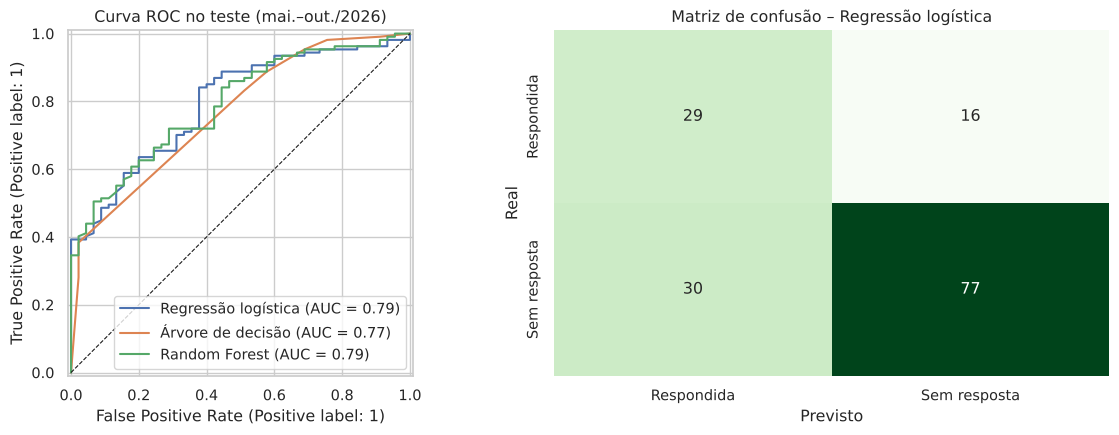

Melhor modelo (maior AUC, desempate pelo F1): Regressão logística


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for nome, m in modelos.items():
    if not nome.startswith('Referência'):
        RocCurveDisplay.from_estimator(m, Xte, yte, name=nome, ax=ax[0])
ax[0].plot([0, 1], [0, 1], 'k--', lw=.8); ax[0].set_title('Curva ROC no teste (mai.–out./2026)')
melhor = metricas.drop(index='Referência (aleatória)').sort_values(['auc', 'f1'], ascending=False).index[0]
cm = confusion_matrix(yte, modelos[melhor].predict(Xte))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax[1],
            xticklabels=['Respondida', 'Sem resposta'], yticklabels=['Respondida', 'Sem resposta'])
ax[1].set_xlabel('Previsto'); ax[1].set_ylabel('Real'); ax[1].set_title(f'Matriz de confusão – {melhor}')
plt.tight_layout(); plt.show()
print('Melhor modelo (maior AUC, desempate pelo F1):', melhor)

In [15]:
# Regras da árvore: podem virar regras simples no painel do síndico
arv = modelos['Árvore de decisão']
nomes_feat = list(arv[0].get_feature_names_out())
print(export_text(arv[-1], feature_names=[n.split('__')[1] for n in nomes_feat], decimals=1))
coef = pd.Series(modelos['Regressão logística'][-1].coef_[0],
                 index=[n.split('__')[1] for n in modelos['Regressão logística'][0].get_feature_names_out()]).sort_values()
print('Coeficientes da regressão logística (positivo = mais chance de ficar sem resposta):')
print(pd.concat([coef.head(5), coef.tail(5)]).round(2).to_string())

|--- categoria_Barulho <= 0.5
|   |--- categoria_Manutenção <= 0.5
|   |   |--- categoria_Vazamento e infiltração <= 0.5
|   |   |   |--- registrado_por_Zeladoria <= 0.5
|   |   |   |   |--- class: 1
|   |   |   |--- registrado_por_Zeladoria >  0.5
|   |   |   |   |--- class: 0
|   |   |--- categoria_Vazamento e infiltração >  0.5
|   |   |   |--- carga_30d <= 30.5
|   |   |   |   |--- class: 0
|   |   |   |--- carga_30d >  30.5
|   |   |   |   |--- class: 0
|   |--- categoria_Manutenção >  0.5
|   |   |--- recorrente <= 0.5
|   |   |   |--- registrado_por_Portaria <= 0.5
|   |   |   |   |--- class: 0
|   |   |   |--- registrado_por_Portaria >  0.5
|   |   |   |   |--- class: 0
|   |   |--- recorrente >  0.5
|   |   |   |--- carga_30d <= 30.5
|   |   |   |   |--- class: 0
|   |   |   |--- carga_30d >  30.5
|   |   |   |   |--- class: 0
|--- categoria_Barulho >  0.5
|   |--- local_Pilotis <= 0.5
|   |   |--- carga_30d <= 30.5
|   |   |   |--- recorrente <= 0.5
|   |   |   |   |--- class

**Leitura:** os três modelos ficam acima da referência (AUC 0,77–0,79 contra 0,55). A **regressão logística** foi
escolhida: maior AUC (0,79), recall 0,72 e precisão 0,83, e é a mais fácil de explicar ao síndico. Os coeficientes
mostram o padrão: **barulho, animais e registros de morador** aumentam a chance de ficar sem resposta; **manutenção,
vazamento e registros da zeladoria** diminuem.

## Fase 5 – Avaliação

Os resultados são confrontados com os critérios definidos na Fase 1.

In [16]:
crit = pd.DataFrame([
    ['Concordância da categorização ≥ 80%', f'{concord:.1%}', concord >= .80],
    ['0 identificadores na base final', str(int(df.resumo.str.contains(padrao_id).sum())), df.resumo.str.contains(padrao_id).sum() == 0],
    [f'Recall ≥ 0,70 ({melhor})', f'{metricas.loc[melhor, "recall"]:.2f}', metricas.loc[melhor, 'recall'] >= .70],
    [f'AUC ≥ 0,70 ({melhor})', f'{metricas.loc[melhor, "auc"]:.2f}', metricas.loc[melhor, 'auc'] >= .70],
    ['F1 acima da referência', f'{metricas.loc[melhor, "f1"]:.2f} × {metricas.loc["Referência (aleatória)", "f1"]:.2f}',
     metricas.loc[melhor, 'f1'] > metricas.loc['Referência (aleatória)', 'f1']],
], columns=['Critério', 'Resultado', 'Atingido'])
print(crit.to_string(index=False))

                           Critério   Resultado  Atingido
Concordância da categorização ≥ 80%       86.1%      True
    0 identificadores na base final           0      True
Recall ≥ 0,70 (Regressão logística)        0.72      True
   AUC ≥ 0,70 (Regressão logística)        0.79      True
             F1 acima da referência 0.77 × 0.73      True


**Revisão de falhas:** o modelo erra igual em todas as categorias? E a proporção de alertas é compatível com a
proporção real de ocorrências sem resposta no teste?

In [17]:
aval = teste.assign(pred=modelos[melhor].predict(Xte), prob=modelos[melhor].predict_proba(Xte)[:, 1])
print(f'Sem resposta real no teste: {yte.mean():.1%} · média da probabilidade prevista: {aval.prob.mean():.1%} · '
      f'alertas: {aval.pred.mean():.1%} das ocorrências')
por_cat = aval.groupby('categoria').agg(n=('id_registro', 'size'), real=('sem_resposta', 'mean'), previsto=('prob', 'mean'))
print(por_cat.round(2).sort_values('real', ascending=False).to_string())

Sem resposta real no teste: 70.4% · média da probabilidade prevista: 57.6% · alertas: 61.2% das ocorrências
                          n  real  previsto
categoria                                  
Barulho                  42  0.98      0.87
Animais                  11  0.91      0.71
Lixo e limpeza           13  0.77      0.60
Convivência e regras     12  0.67      0.48
Não identificada          3  0.67      0.48
Garagem e vagas          23  0.61      0.62
Vazamento e infiltração  12  0.58      0.28
Segurança e acesso        9  0.56      0.37
Encomendas e portaria     5  0.40      0.47
Manutenção               22  0.36      0.22


**Leitura:** no teste, 70% ficou sem resposta, mas o modelo alerta 61% das ocorrências: ele é **conservador**
(o `class_weight='balanced'` puxa as probabilidades para o meio). Os erros se concentram em vazamento, segurança e
manutenção, em que o teste teve mais ocorrências sem resposta do que o histórico indicava.

**Iteração (volta à Fase 4):** o sistema não terá ML, então a pergunta prática é: **uma regra simples basta?**
Comparo o modelo completo com uma regressão logística que usa **só a categoria** – equivalente a uma tabela "taxa de
resposta por categoria" que o painel pode mostrar sem modelo nenhum.

In [18]:
so_cat = make_pipeline(ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), ['categoria'])]),
                       LogisticRegression(max_iter=2000, C=.5, class_weight='balanced')).fit(Xtr, ytr)
p2, prob2 = so_cat.predict(Xte), so_cat.predict_proba(Xte)[:, 1]
iteracao = pd.DataFrame({'modelo completo': metricas.loc['Regressão logística', ['recall', 'precisao', 'f1', 'auc']],
                         'só a categoria': [recall_score(yte, p2), precision_score(yte, p2), f1_score(yte, p2),
                                            roc_auc_score(yte, prob2)]})
print(iteracao.round(3).to_string())

          modelo completo  só a categoria
recall              0.720           0.738
precisao            0.828           0.814
f1                  0.770           0.775
auc                 0.794           0.783


**Leitura da iteração:** usar **só a categoria** dá praticamente o mesmo resultado (AUC 0,78 × 0,79; F1 0,78 × 0,77).
A informação útil está quase toda na categoria. Para o sistema, isso é uma boa notícia: em vez de um modelo, basta o
painel mostrar a **taxa de resposta histórica de cada categoria** e destacar as que costumam ficar sem retorno.

## Fase 6 – Implementação

### 6.1 O que vai para o sistema (painel do síndico)

O sistema do projeto **não terá ML** (escopo). A implementação desta análise é:
1. **Indicadores do painel** = consultas KPI 1–7 do `livro_ocorrencias.sql`, que o Arthur usa no painel. A importação do
   histórico do livro precisa dar os mesmos números deste notebook (critério "indicadores reproduzíveis").
2. **Regras simples** tiradas do modelo, mostradas como destaque no painel:
   - ocorrência das categorias com menor taxa de resposta (Barulho, Animais, Lixo e limpeza) ou registrada à noite →
     selo "atenção: costuma ficar sem retorno";
   - mesma categoria no mesmo local em 30 dias → selo "recorrente: avaliar manutenção preventiva".
3. **Prazo de resposta proposto:** a mediana atual de dias até a resposta vira a meta inicial do síndico.

Abaixo, o protótipo dessas regras aplicado às ocorrências de **outubro de 2026**.

In [19]:
CATS_ATENCAO = [str(c) for c in resp_cat.drop(index='Não identificada', errors='ignore').index[:3]]
out = df[df.mes == pd.Period('2026-10', 'M')].copy()
out['atencao'] = out.categoria.isin(CATS_ATENCAO) | out.noturno
out['selo_recorrente'] = out.recorrente
out['risco_modelo'] = modelos[melhor].predict_proba(out[cat_cols + num_cols].astype({c: float for c in num_cols}))[:, 1]
prazo = int(np.ceil(df.dias_ate_resposta.median()))
print(f'Categorias de atenção: {CATS_ATENCAO} · prazo proposto: {prazo} dias')
print(f'Outubro/2026: {len(out)} ocorrências, {out.atencao.sum()} com selo de atenção, {out.selo_recorrente.sum()} recorrentes')
print(f'Concordância entre a regra simples e o modelo (risco ≥ 0,5): {((out.risco_modelo >= .5) == out.atencao).mean():.0%}')
painel_out = out[['id_registro', 'data', 'categoria', 'local', 'atencao', 'selo_recorrente', 'risco_modelo', 'houve_resposta']]
painel_out.head(10).round(2)

Categorias de atenção: ['Barulho', 'Animais', 'Lixo e limpeza'] · prazo proposto: 4 dias
Outubro/2026: 24 ocorrências, 7 com selo de atenção, 10 recorrentes
Concordância entre a regra simples e o modelo (risco ≥ 0,5): 75%


,id_registro,data,categoria,local,atencao,selo_recorrente,risco_modelo,houve_resposta
615,628,2026-10-03,Barulho,Salão de festas,True,False,0.94,não
616,629,2026-10-04,Segurança e acesso,Portão,False,False,0.31,sim
617,630,2026-10-04,Garagem e vagas,Não informado,False,False,0.49,não
618,631,2026-10-04,Garagem e vagas,Garagem,False,True,0.71,sim
619,632,2026-10-09,Manutenção,Escadas,False,False,0.21,sim
620,633,2026-10-10,Barulho,Unidade (6º andar),True,True,0.94,não
621,634,2026-10-11,Garagem e vagas,Garagem,False,True,0.71,não
622,635,2026-10-14,Garagem e vagas,Garagem,False,True,0.57,não
623,636,2026-10-16,Vazamento e infiltração,Telhado e caixa d'água,False,False,0.16,não
624,637,2026-10-17,Barulho,Pilotis,True,False,0.88,não


### 6.2 Monitoramento

Depois do piloto, os mesmos indicadores são recalculados com os registros do sistema (H5: a taxa de resposta aumenta
com o registro digital?). Para acompanhar mudanças, comparo a distribuição de categorias do último semestre com a do
primeiro ano (diferença em pontos percentuais).

In [20]:
ano1 = df[df.data < '2025-11-01'].categoria.value_counts(normalize=True)
ult = df[df.data >= '2026-05-01'].categoria.value_counts(normalize=True)
mudanca = ((ult - ano1) * 100).sort_values()
print(mudanca.round(1).to_string())

categoria
Vazamento e infiltração   -4.6
Manutenção                -3.0
Encomendas e portaria     -1.7
Não identificada          -1.5
Segurança e acesso        -1.0
Garagem e vagas           -0.5
Animais                    0.0
Convivência e regras       0.4
Lixo e limpeza             3.2
Barulho                    8.6


## Dashboard (Pandas + Matplotlib + Seaborn)

No lugar do Power BI, o dashboard é montado em Python com as bibliotecas da disciplina: **Pandas** agrega, **Seaborn**
desenha (`barplot`, `heatmap`, `lineplot`, `regplot`) e **Matplotlib** monta as páginas. São as mesmas visões que o
painel do síndico, feito pelo Arthur no sistema, vai mostrar. As páginas são salvas em `Dashboard/`.

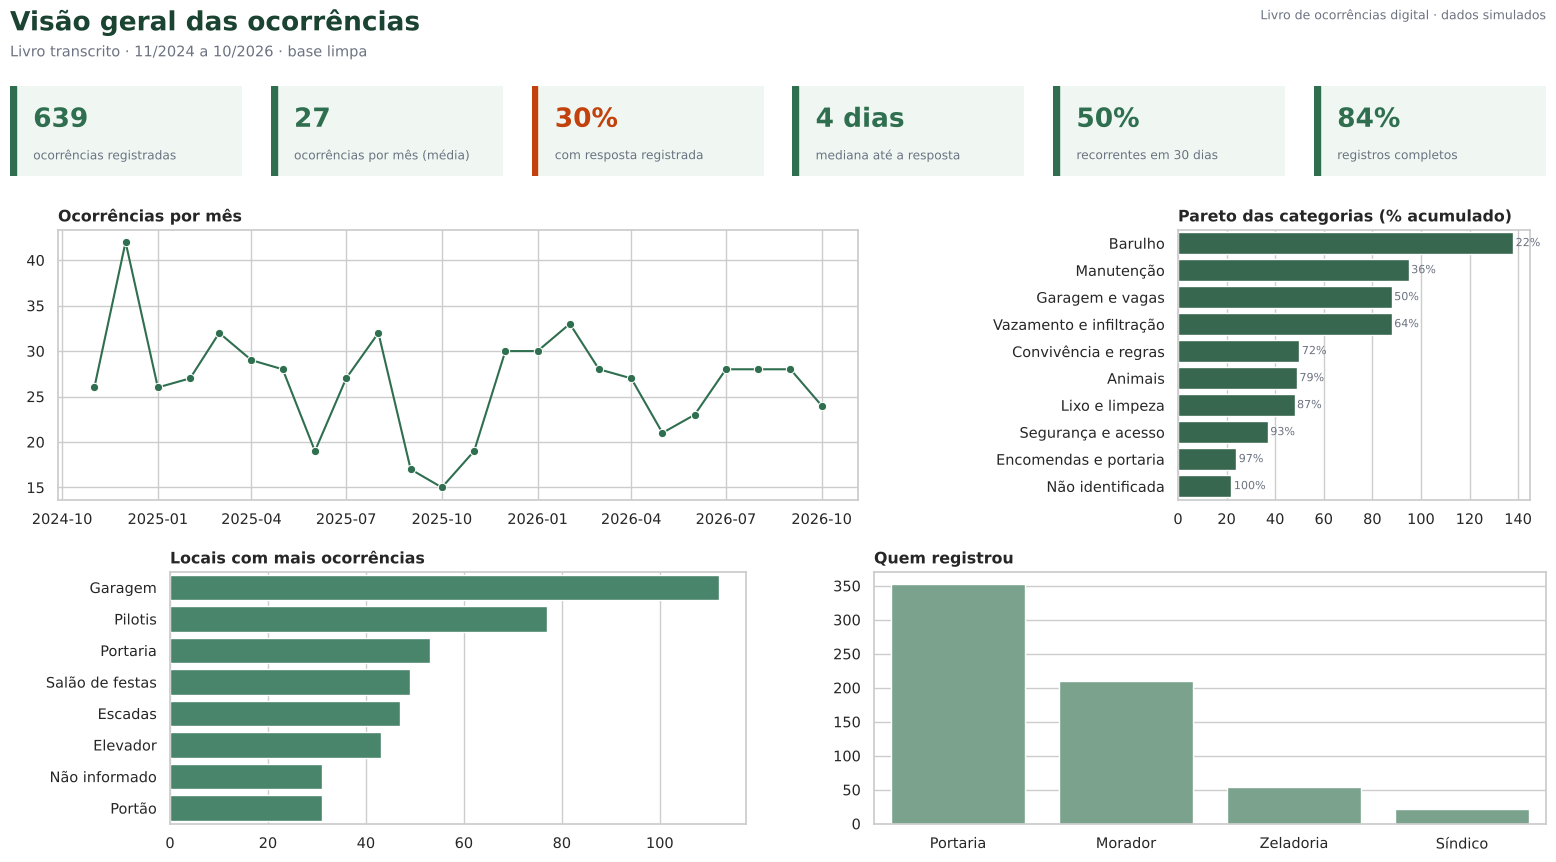

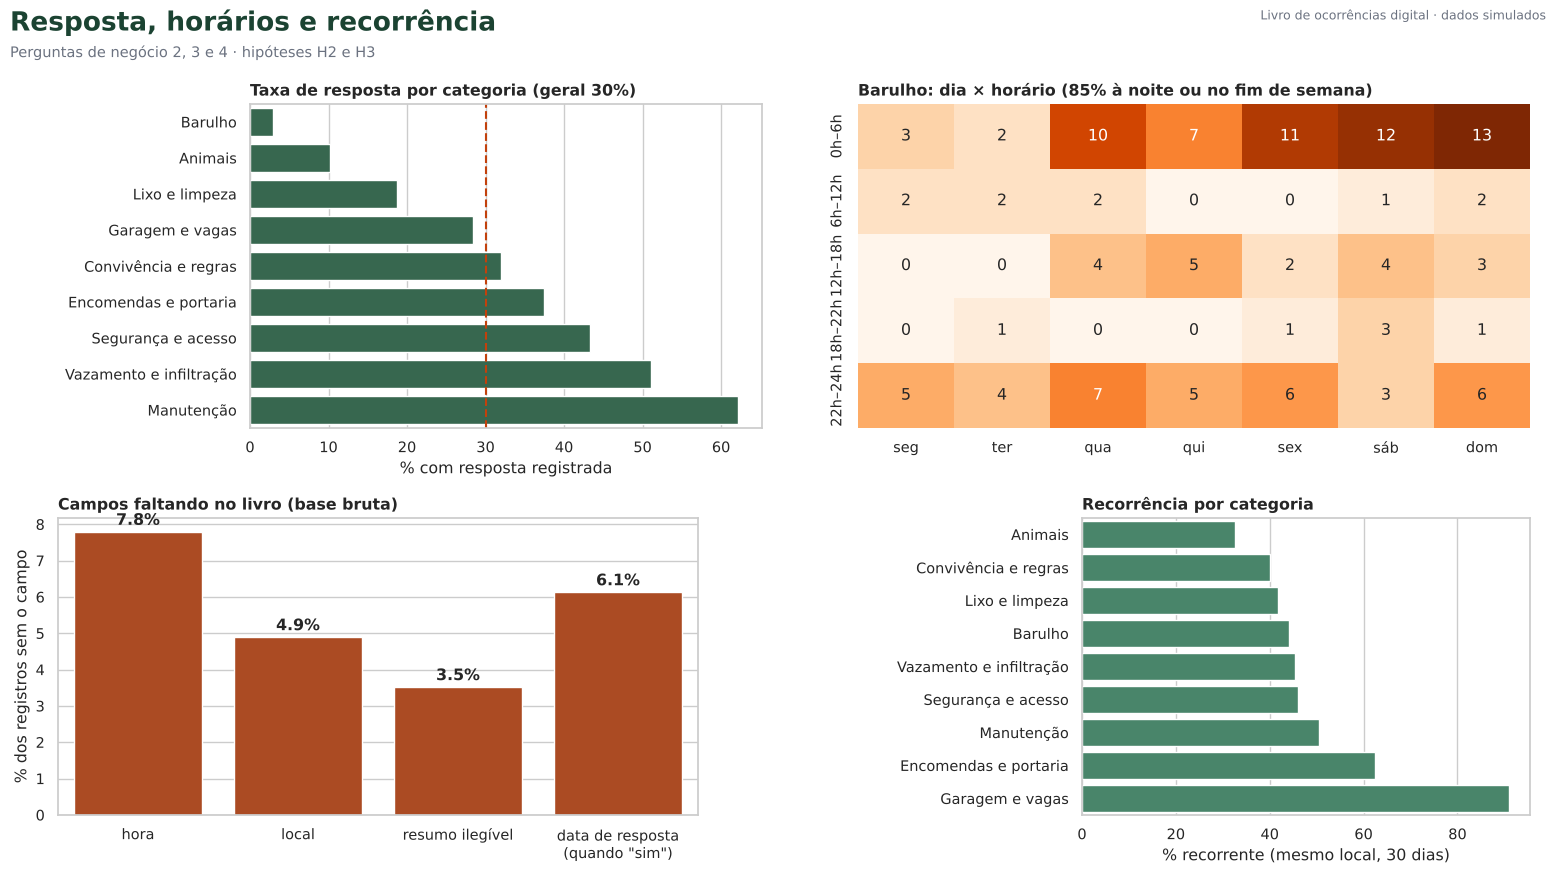

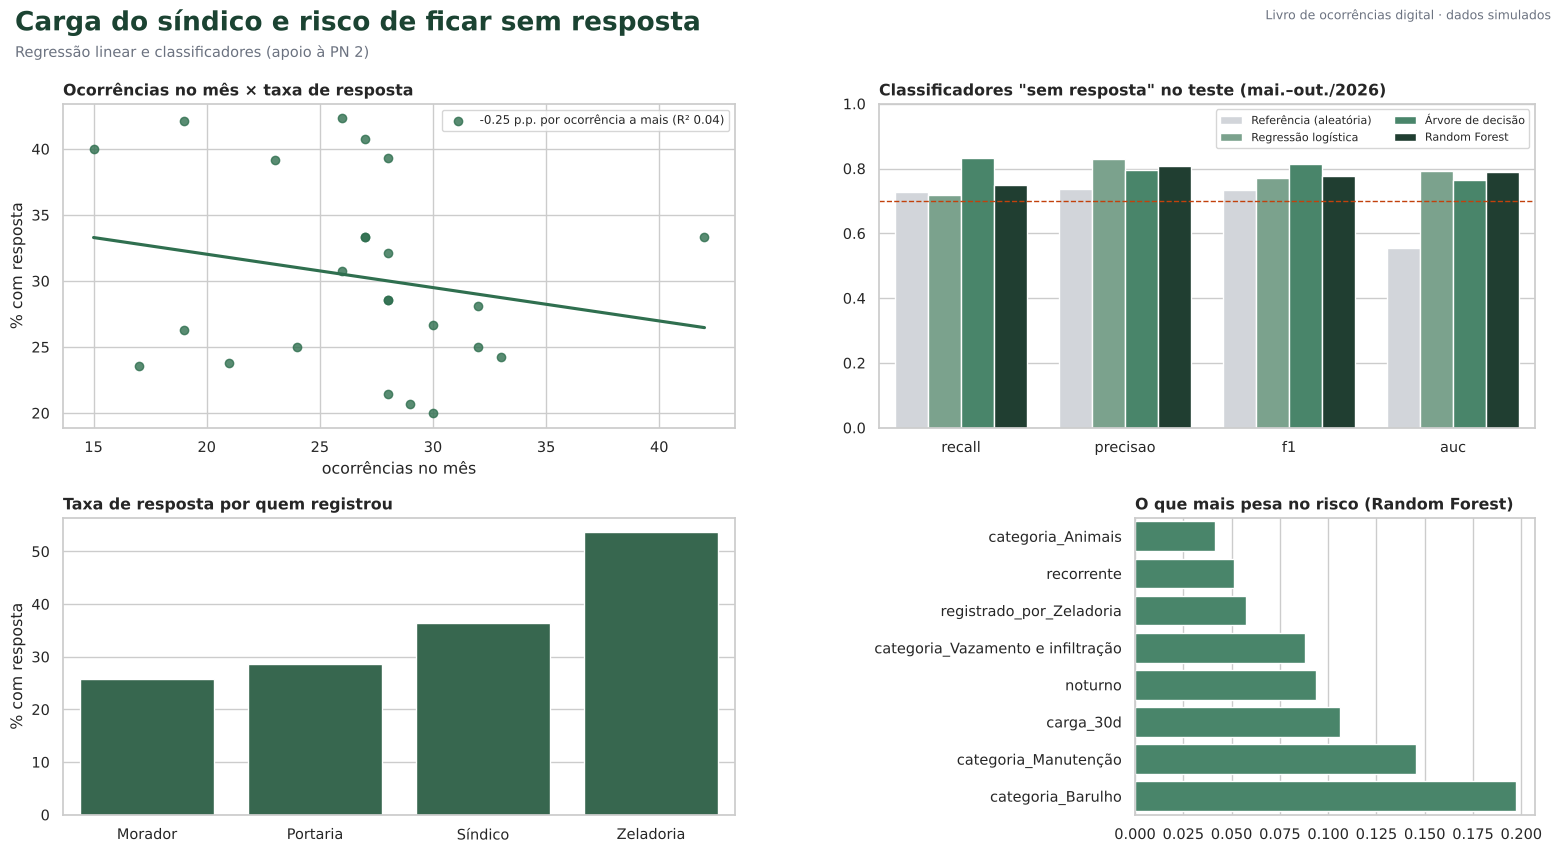

In [21]:
VERDE, VERDE_ESC, LARANJA, CINZA = '#2f6f4f', '#1b4332', '#c2410c', '#6b7280'

def cabecalho(fig, titulo, sub):
    fig.patch.set_facecolor('white')
    fig.text(.02, .965, titulo, fontsize=19, weight='bold', color=VERDE_ESC, va='top')
    fig.text(.02, .925, sub, fontsize=10.5, color=CINZA, va='top')
    fig.text(.98, .965, 'Livro de ocorrências digital · dados simulados', fontsize=9, color=CINZA, ha='right', va='top')

def cartao(fig, x, y, valor, rotulo, cor=VERDE):
    ax = fig.add_axes([x, y, .145, .1]); ax.axis('off')
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color='#f0f7f3', zorder=0))
    ax.add_patch(plt.Rectangle((0, 0), .025, 1, transform=ax.transAxes, color=cor))
    ax.text(.1, .62, valor, fontsize=19, weight='bold', color=cor, transform=ax.transAxes, va='center')
    ax.text(.1, .22, rotulo, fontsize=8.8, color=CINZA, transform=ax.transAxes, va='center')

# ---------- Página 1: visão geral ----------
fig = plt.figure(figsize=(16, 9))
cabecalho(fig, 'Visão geral das ocorrências', f'Livro transcrito · {df.data.min():%m/%Y} a {df.data.max():%m/%Y} · base limpa')
cards = [(f'{len(df)}', 'ocorrências registradas'), (f'{len(df) / df.mes.nunique():.0f}', 'ocorrências por mês (média)'),
         (f'{taxa_resp:.0%}', 'com resposta registrada'), (f'{df.dias_ate_resposta.median():.0f} dias', 'mediana até a resposta'),
         (f'{df.recorrente.mean():.0%}', 'recorrentes em 30 dias'), (f'{df.completo.mean():.0%}', 'registros completos')]
for i, (v, r) in enumerate(cards):
    cartao(fig, .02 + i * .163, .78, v, r, LARANJA if i == 2 else VERDE)
ax1 = fig.add_axes([.05, .42, .5, .3])
serie = df.groupby(df.mes.dt.to_timestamp()).size()
sns.lineplot(x=serie.index, y=serie.values, marker='o', color=VERDE, ax=ax1)
ax1.set_title('Ocorrências por mês', loc='left', weight='bold'); ax1.set_xlabel(''); ax1.set_ylabel('')
ax2 = fig.add_axes([.75, .42, .22, .3])
sns.barplot(x=pareto.ocorrencias.values, y=pareto.index, color=VERDE, ax=ax2)
ax2.set_title('Pareto das categorias (% acumulado)', loc='left', weight='bold'); ax2.set_xlabel(''); ax2.set_ylabel('')
for i, (v, p) in enumerate(zip(pareto.ocorrencias, pareto.perc_acumulado)):
    ax2.text(v + 1, i, f'{p:.0f}%', va='center', fontsize=8, color=CINZA)
ax3 = fig.add_axes([.12, .06, .36, .28])
sns.barplot(x=loc.values[:8], y=loc.index[:8], color='#3f8f6b', ax=ax3)
ax3.set_title('Locais com mais ocorrências', loc='left', weight='bold'); ax3.set_ylabel('')
ax4 = fig.add_axes([.56, .06, .42, .28])
quem = df.registrado_por.value_counts()
sns.barplot(x=quem.index, y=quem.values, color='#74a98c', ax=ax4); ax4.set_title('Quem registrou', loc='left', weight='bold'); ax4.set_xlabel(''); ax4.set_ylabel('')
fig.savefig(os.path.join(DASH, '01_visao_geral.png'), dpi=110); plt.show()

# ---------- Página 2: resposta, horários e recorrência ----------
fig = plt.figure(figsize=(16, 9))
cabecalho(fig, 'Resposta, horários e recorrência', 'Perguntas de negócio 2, 3 e 4 · hipóteses H2 e H3')
ax1 = fig.add_axes([.17, .5, .32, .36])
rc = resp_cat.drop(index='Não identificada', errors='ignore').sort_values('taxa_resposta')
sns.barplot(x=rc.taxa_resposta * 100, y=rc.index, color=VERDE, ax=ax1)
ax1.axvline(taxa_resp * 100, ls='--', color=LARANJA); ax1.set_xlabel('% com resposta registrada'); ax1.set_ylabel('')
ax1.set_title(f'Taxa de resposta por categoria (geral {taxa_resp:.0%})', loc='left', weight='bold')
ax2 = fig.add_axes([.55, .5, .42, .36])
sns.heatmap(calor_b, annot=True, fmt='.0f', cmap='Oranges', cbar=False, ax=ax2)
ax2.set_title(f'Barulho: dia × horário ({h3:.0%} à noite ou no fim de semana)', loc='left', weight='bold')
ax2.set_xlabel(''); ax2.set_ylabel('')
ax3 = fig.add_axes([.05, .07, .4, .33])
falta = pd.Series({'hora': livro.hora.isna().mean(), 'local': livro.local.isna().mean(),
                   'resumo ilegível': (livro.resumo == '[ilegível]').mean(),
                   'data de resposta\n(quando "sim")': ((livro.houve_resposta == 'sim') & livro.data_resposta.isna()).sum()
                   / (livro.houve_resposta == 'sim').sum()}) * 100
sns.barplot(x=falta.index, y=falta.values, color=LARANJA, ax=ax3)
ax3.set_xlabel(''); ax3.set_ylabel('% dos registros sem o campo'); ax3.set_title('Campos faltando no livro (base bruta)', loc='left', weight='bold')
for i, v in enumerate(falta.values):
    ax3.text(i, v + .2, f'{v:.1f}%', ha='center', weight='bold')
ax4 = fig.add_axes([.69, .07, .28, .33])
rr = (recor.drop(index='Não identificada', errors='ignore') * 100).sort_values()
sns.barplot(x=rr.values, y=rr.index, color='#3f8f6b', ax=ax4); ax4.set_xlabel('% recorrente (mesmo local, 30 dias)')
ax4.set_title('Recorrência por categoria', loc='left', weight='bold'); ax4.set_ylabel('')
fig.savefig(os.path.join(DASH, '02_resposta_horarios.png'), dpi=110); plt.show()

# ---------- Página 3: dispersão e modelos ----------
fig = plt.figure(figsize=(16, 9))
cabecalho(fig, 'Carga do síndico e risco de ficar sem resposta', 'Regressão linear e classificadores (apoio à PN 2)')
ax1 = fig.add_axes([.05, .5, .42, .36])
sns.regplot(data=mensal, x='ocorrencias', y='taxa_resposta_%', ax=ax1, color=VERDE, ci=None,
            label=f'{m_all.coef_[0]:.2f} p.p. por ocorrência a mais (R² {r2_all:.2f})')
ax1.legend(fontsize=8.5); ax1.set_xlabel('ocorrências no mês'); ax1.set_ylabel('% com resposta')
ax1.set_title('Ocorrências no mês × taxa de resposta', loc='left', weight='bold')
ax2 = fig.add_axes([.56, .5, .41, .36])
mm = metricas[['recall', 'precisao', 'f1', 'auc']].reset_index().melt(id_vars='modelo')
sns.barplot(data=mm, x='variable', y='value', hue='modelo', palette=['#d1d5db', '#74a98c', '#3f8f6b', VERDE_ESC], ax=ax2)
ax2.axhline(.7, ls='--', color=LARANJA, lw=1); ax2.set_ylim(0, 1); ax2.set_xlabel(''); ax2.set_ylabel('')
ax2.legend(fontsize=8, ncol=2); ax2.set_title('Classificadores "sem resposta" no teste (mai.–out./2026)', loc='left', weight='bold')
ax3 = fig.add_axes([.05, .07, .42, .33])
pq = (por_quem.taxa_resposta * 100)
sns.barplot(x=pq.index, y=pq.values, color=VERDE, ax=ax3)
ax3.set_xlabel(''); ax3.set_ylabel('% com resposta')
ax3.set_title('Taxa de resposta por quem registrou', loc='left', weight='bold')
ax4 = fig.add_axes([.72, .07, .25, .33])
imp = pd.Series(modelos['Random Forest'][-1].feature_importances_,
                index=[n.split('__')[1] for n in modelos['Random Forest'][0].get_feature_names_out()]).sort_values().tail(8)
sns.barplot(x=imp.values, y=imp.index, color='#3f8f6b', ax=ax4)
ax4.set_title('O que mais pesa no risco (Random Forest)', loc='left', weight='bold'); ax4.set_ylabel('')
fig.savefig(os.path.join(DASH, '03_dispersao_modelos.png'), dpi=110); plt.show()

### Exportação dos dados (pasta `dados/`)

Salva a base bruta transcrita (com os problemas, usada pelas validações do `livro_ocorrencias.sql`) e as tabelas
processadas.

In [22]:
proc = os.path.join(DADOS, 'processed')
cols_limpa = ['id_registro', 'data', 'hora', 'registrado_por', 'local', 'categoria', 'resumo', 'houve_resposta',
              'data_resposta', 'desfecho', 'noturno', 'fim_de_semana', 'carga_30d', 'recorrente', 'completo', 'dias_ate_resposta']
df[cols_limpa].to_csv(os.path.join(proc, 'ocorrencias_limpas.csv'), index=False)
pareto.to_csv(os.path.join(proc, 'pareto_categorias.csv'))
mensal.drop(columns='taxa_resposta_%').to_csv(os.path.join(proc, 'indicadores_mensais.csv'), index=False)
metricas.to_csv(os.path.join(proc, 'metricas_modelos.csv'))
painel_out.to_csv(os.path.join(proc, 'prototipo_selos_out2026.csv'), index=False)
resumo = {'ocorrencias_brutas': int(len(livro)), 'ocorrencias_limpas': int(len(df)), 'qualidade': qualidade.to_dict(),
          'concordancia': round(float(concord), 4), 'kappa': round(float(kappa), 4), 'top3_perc': round(float(top3), 2),
          'taxa_resposta': round(float(taxa_resp), 4), 'mediana_dias': float(df.dias_ate_resposta.median()),
          'h3_barulho_noite_fds': round(float(h3), 4), 'recorrencia': round(float(df.recorrente.mean()), 4),
          'completude': round(float(df.completo.mean()), 4), 'por_quem_registrou': por_quem.round(4).to_dict(),
          'regressao_mensal': {'inclinacao_pp': round(float(m_all.coef_[0]), 4), 'r2': round(float(r2_all), 4),
                               'dias_inclinacao': round(float(m_d.coef_[0]), 4), 'dias_r2': round(float(r2_d), 4)},
          'metricas': metricas.round(4).to_dict(orient='index'), 'melhor_modelo': melhor,
          'iteracao': iteracao.round(4).to_dict(), 'categorias_atencao': CATS_ATENCAO, 'prazo_proposto_dias': prazo}
with open(os.path.join(proc, 'resumo_resultados.json'), 'w', encoding='utf-8') as f:
    json.dump(resumo, f, ensure_ascii=False, indent=2, default=str)
print(sorted(os.listdir(DADOS)), sorted(os.listdir(proc)))

['livro_ocorrencias_transcrito.csv', 'processed'] ['indicadores_mensais.csv', 'metricas_modelos.csv', 'ocorrencias_limpas.csv', 'pareto_categorias.csv', 'prototipo_selos_out2026.csv', 'resumo_resultados.json']


## Conclusão da parte prática

O notebook percorreu as seis fases do CRISP-DM sobre a estrutura planejada para a transcrição do livro: verificou a
qualidade, limpou e anonimizou a base, respondeu às perguntas de negócio 1 a 4, testou as hipóteses H1 a H3 e avaliou se
o risco de uma ocorrência ficar sem resposta é previsível. O resumo dos números e a discussão estão no `README.md` do
projeto. **Próximo passo:** trocar a Seção 2.1 pela leitura da transcrição real e rodar tudo de novo; depois do piloto,
repetir os indicadores com os registros do sistema para testar a H5. A PN 5 e a H4 ficam para quando o questionário
com os moradores for aplicado.